# Project 1. CIFAR-10 residual network

[Project repository](https://github.com/Mo-Awadalla/new-york-knicks-cifar10)

This notebook analyzes the submitted WRN-22-4 student and the recorded experiments. The final model trained on all 50,000 training images. A separate model trained on 45,000 images supplies the held-out validation results. Kaggle reports the test scores. Hidden test labels are not available locally.

The default run uses aggregate evidence in `results/` and does not require images or checkpoints. An optional replay below evaluates the original validation checkpoint against the 5,000 held-out images.

In [1]:
from pathlib import Path
import csv
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch

%matplotlib inline

cwd = Path.cwd()
if (cwd / "results" / "SHA256SUMS").is_file() and (cwd / "src" / "knicks_cifar.py").is_file():
    root = cwd
elif cwd.name == "notebooks" and (cwd.parent / "results" / "SHA256SUMS").is_file() and (cwd.parent / "src" / "knicks_cifar.py").is_file():
    root = cwd.parent
else:
    raise RuntimeError("Run the notebook from the repository root or notebooks directory")
sys.path.insert(0, str(root / "src"))
sys.path.insert(0, str(root / "scripts"))
import knicks_cifar as kc
from project1_evidence import load_evidence

results = root / "results"
evidence = load_evidence(results)
final = evidence.final
validation = evidence.validation
curves = evidence.curves
val_manifest = json.loads((results / "final-validation-manifest.json").read_text())
with (results / "kaggle-submissions.csv").open(newline="", encoding="utf-8") as stream:
    submissions = list(csv.DictReader(stream))
print("Aggregate evidence checksums and consistency checked.")

Aggregate evidence checksums and consistency checked.


## Model and reported scores

The student is a pre-activation Wide ResNet with depth 22 and width 4. It has three groups of residual blocks, global average pooling, and a 10-class linear head. The parameter count below comes from a new instance of the actual model, not from the saved manifest.

The separate validation model and final full-data model use the same recipe but different checkpoints. The full-data model has no held-out validation score. The private and public scores below are Kaggle-reported scores for submission 57968810. They are not computed from local hidden labels.

In [2]:
model = kc.build(final.arch)
parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert parameter_count == kc.trainable_params(model) == final.params == 4_298_970
matches = [row for row in submissions if row["ref"] == str(final.submission_ref)]
if len(matches) != 1 or matches[0]["status"] != "SubmissionStatus.COMPLETE":
    raise ValueError("Expected one completed final Kaggle submission")
submission = matches[0]
if (float(submission["privateScore"]) != final.private_accuracy or
        float(submission["publicScore"]) != final.public_accuracy):
    raise ValueError("Kaggle submission scores differ from the final evidence")
print(f"Architecture: WRN-22-4. Independently counted trainable parameters: {parameter_count:,}")
print(f"Kaggle-reported PRIVATE test accuracy: {100 * float(submission['privateScore']):.2f}%")
print(f"Kaggle-reported public test accuracy: {100 * float(submission['publicScore']):.2f}%")
print(f"Separate held-out validation model: {100 * validation.accuracy:.2f}% ({validation.correct:,}/{validation.rows:,})")
print(f"Final full-data checkpoint SHA-256: {final.checkpoint_sha256}")
print(f"Separate validation checkpoint SHA-256: {validation.checkpoint_sha256}")

Architecture: WRN-22-4. Independently counted trainable parameters: 4,298,970
Kaggle-reported PRIVATE test accuracy: 85.90%
Kaggle-reported public test accuracy: 88.40%
Separate held-out validation model: 97.44% (4,872/5,000)
Final full-data checkpoint SHA-256: 9a5a28fa5e00dc4e929d5f0b25f7c3bd14a5123c43d6cb6409407be039460a49
Separate validation checkpoint SHA-256: 42fa268b43159b51eb9a936f9d00e91a5cfdd0194e7abb884bb79333658f9719


## Training and comparison

The final student used 200 epochs with seed 1, batch size 128, SGD with Nesterov momentum 0.9, learning rate 0.1, five warmup epochs, cosine decay, and weight decay 0.0005. CutMix used probability 0.5 and alpha 1. Distillation used alpha 0.9 and temperature 4 with averaged teacher probabilities. The two scratch-trained WRN-28-10 teachers used CutMix and SAM with Cutout. Each teacher had 36,479,194 parameters and neither was used for final inference. Staff did not confirm whether the parameter cap exempts teachers.

The table keeps held-out validation distinct from Kaggle scores. Some Kaggle scores use full-data retrains rather than the validation checkpoint. A blank score means no corresponding submission was recorded. Each comparison uses one seed, and the validation split was reused across experiments.

In [3]:
def score(value):
    return "--" if value is None else f"{100 * value:.2f}%"

print(f"{'Experiment':30} {'Seed':>4} {'Validation':>11} {'Public':>9} {'Private':>9} {'Test train rows':>15}")
for experiment in evidence.experiments:
    test_rows = experiment["test_training_rows"]
    print(f"{experiment['name']:30} {experiment['seed']:4d} "
          f"{score(experiment['validation_accuracy']):>11} "
          f"{score(experiment['public_accuracy']):>9} "
          f"{score(experiment['private_accuracy']):>9} "
          f"{str(test_rows) if test_rows is not None else '--':>15}")

Experiment                     Seed  Validation    Public   Private Test train rows
Crop and flip                     0      95.38%    84.90%    83.40%           45000
Cutout                            0      96.36%    86.30%    84.50%           45000
WRN-22-4 Cutout                   0      96.32%        --        --              --
Matched Cutout control            1      96.46%        --        --              --
SAM with Cutout                   1      96.92%    87.40%    85.50%           50000
CutMix                            1      96.74%    87.90%    85.70%           50000
Small-teacher distillation        1      97.32%    87.50%    85.30%           50000
Large-teacher distillation        1      97.44%    88.40%    85.90%           50000


## Validation learning curves

These curves use the recorded epoch-level held-out accuracy. The large-teacher run is the validation counterpart of the final recipe, not the full-data checkpoint. Different methods and seeds limit causal comparisons.

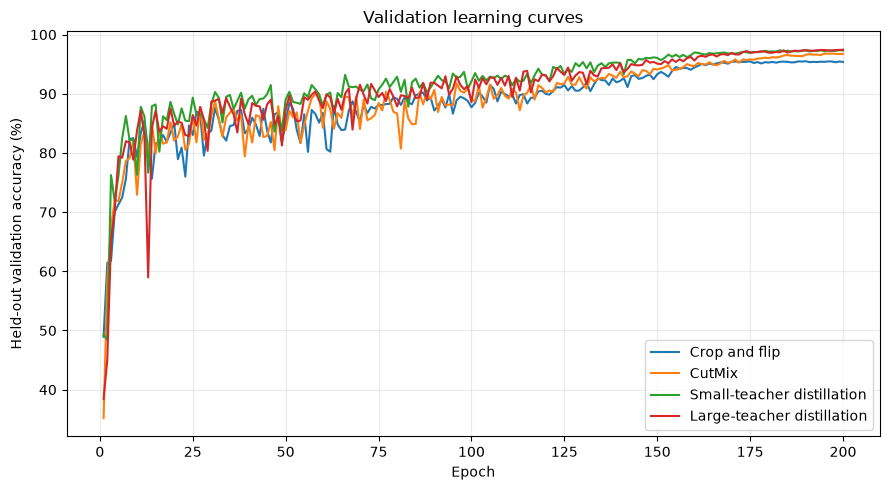

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
for name in ("Crop and flip", "CutMix", "Small-teacher distillation", "Large-teacher distillation"):
    records = curves[name]
    ax.plot([row["epoch"] for row in records],
            [100 * row["val_accuracy"] for row in records], label=name)
ax.set(xlabel="Epoch", ylabel="Held-out validation accuracy (%)", title="Validation learning curves")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

## Validation confusion matrix

Rows are true class IDs and columns are predicted class IDs. The matrix summarizes the separate 45,000-row training run. It is not a test confusion matrix.

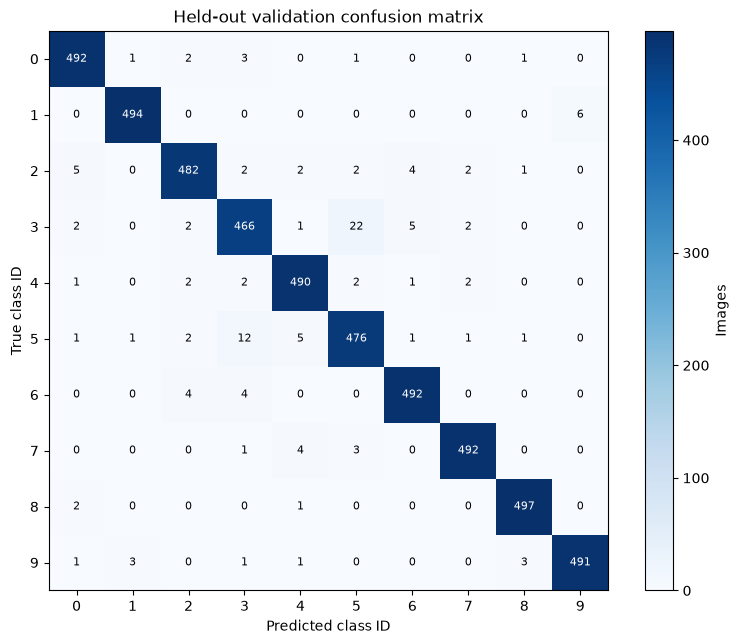

In [5]:
counts = np.asarray(evidence.confusion, dtype=np.int64)
classes = list(range(10))
fig, ax = plt.subplots(figsize=(8, 6.5))
image = ax.imshow(counts, cmap="Blues")
ax.set(xticks=range(10), yticks=range(10), xticklabels=classes, yticklabels=classes,
       xlabel="Predicted class ID", ylabel="True class ID", title="Held-out validation confusion matrix")
for true in range(10):
    for predicted in range(10):
        value = counts[true, predicted]
        ax.text(predicted, true, str(value), ha="center", va="center",
                color="white" if value > counts.max() / 2 else "black", fontsize=8)
fig.colorbar(image, ax=ax, label="Images")
fig.tight_layout()
plt.show()

## Optional validation checkpoint replay

Set both `KNICKS_DATA_ROOT` and `KNICKS_VAL_CHECKPOINT` to replay. The checkpoint directory must also contain its original `val_pred.npy`. Set `KNICKS_DEVICE` to `cpu`, `cuda`, or `mps`. The default is `cpu`. Paths may be relative to the repository root. The replay checks all three official CSV hashes, the checkpoint hash and split fingerprint, every prediction, the confusion matrix, and the correct count. The checkpoint loader and evaluation function use evaluation mode, so batch normalization statistics do not update. No hidden test labels are used.

To check the full-data checkpoint separately, set `KNICKS_FINAL_CHECKPOINT`. This loads the model and checks its hash and parameter count. It does not calculate a score.

```bash
KNICKS_DATA_ROOT=runs/weight-edits-001/data \
KNICKS_VAL_CHECKPOINT=runs/weight-edits-001/source/checkpoint.pt \
KNICKS_FINAL_CHECKPOINT=runs/kd-w28x2-e200-full/hpc/kdw28-full.pt \
KNICKS_DEVICE=mps uv run python scripts/build_notebook.py --out notebooks/project1_analysis.ipynb
```

In [6]:
data_setting = os.environ.get("KNICKS_DATA_ROOT")
val_setting = os.environ.get("KNICKS_VAL_CHECKPOINT")
final_setting = os.environ.get("KNICKS_FINAL_CHECKPOINT")
if bool(data_setting) != bool(val_setting):
    raise ValueError("Set both KNICKS_DATA_ROOT and KNICKS_VAL_CHECKPOINT for replay")
device = kc.device_for(os.environ.get("KNICKS_DEVICE", "cpu"))
if not data_setting:
    print("Validation checkpoint: NOT REPLAYED. Aggregate results only.")
else:
    data_root = root / data_setting
    checkpoint_path = root / val_setting
    predictions_path = checkpoint_path.parent / "val_pred.npy"
    for name in val_manifest["csv_sha256"]:
        csv_path = data_root / name
        if not csv_path.is_file() or kc.sha256_file(csv_path) != val_manifest["csv_sha256"][name]:
            raise ValueError(f"Missing or mismatched official CSV: {name}")
    if not checkpoint_path.is_file() or kc.sha256_file(checkpoint_path) != validation.checkpoint_sha256:
        raise ValueError("Missing or mismatched validation checkpoint")
    if not predictions_path.is_file():
        raise ValueError("Missing original val_pred.npy next to validation checkpoint")
    checkpoint, validation_model, mean, std = kc.checkpoint_model(checkpoint_path, device)
    manifest = kc.read_manifest(data_root / "train_labels.csv", True)
    split = kc.stratified_split(manifest)
    if (split.sha256 != validation.split_sha256 or
            checkpoint["split_sha256"] != split.sha256 or
            checkpoint["provenance"]["csv_sha256"] != val_manifest["csv_sha256"] or
            checkpoint["config"]["split"] != "val"):
        raise ValueError("Validation checkpoint data or split provenance mismatch")
    if len(split.val_rows) != 5000 or manifest.labels is None:
        raise ValueError("Expected 5,000 labeled validation rows")
    images = kc.decode(manifest, split.val_rows, kc.image_index(data_root), device)
    labels = torch.tensor([manifest.labels[row] for row in split.val_rows], device=device)
    local_rows = tuple(range(len(split.val_rows)))
    predictions, loss, correct = kc.evaluate(validation_model, images, labels, local_rows, mean, std, 128)
    predictions = np.asarray(predictions)
    original = np.load(predictions_path, allow_pickle=False)
    if original.shape != (5000,) or not np.array_equal(predictions, original):
        raise ValueError("Replayed predictions differ from original val_pred.npy")
    actual_counts = np.zeros((10, 10), dtype=np.int64)
    np.add.at(actual_counts, (labels.cpu().numpy(), predictions), 1)
    if correct != 4872 or not np.array_equal(actual_counts, counts):
        raise ValueError("Replayed validation accuracy or confusion matrix differs")
    print(f"Validation replay device: {device}")
    print("Matched all 5,000 original validation predictions and the recorded confusion matrix.")
    print(f"Validation replay: {correct:,}/5,000 correct ({100 * correct / 5000:.2f}%).")
    print(f"Validation checkpoint SHA-256: {validation.checkpoint_sha256}")
    print(f"Validation split SHA-256: {split.sha256}. All three official CSV hashes matched.")

if not final_setting:
    print("Final full-data checkpoint: NOT LOADED.")
else:
    final_path = root / final_setting
    if not final_path.is_file() or kc.sha256_file(final_path) != final.checkpoint_sha256:
        raise ValueError("Missing or mismatched final checkpoint")
    final_checkpoint, final_model, _, _ = kc.checkpoint_model(final_path, device)
    final_params = sum(p.numel() for p in final_model.parameters() if p.requires_grad)
    if final_params != parameter_count or final_checkpoint["config"]["split"] != "all":
        raise ValueError("Final checkpoint architecture or split mismatch")
    print(f"Final full-data checkpoint loaded on {device}: {final_params:,} trainable parameters.")
    print(f"Final checkpoint SHA-256: {final.checkpoint_sha256}. No labels scored.")

Validation replay device: mps
Matched all 5,000 original validation predictions and the recorded confusion matrix.
Validation replay: 4,872/5,000 correct (97.44%).
Validation checkpoint SHA-256: 42fa268b43159b51eb9a936f9d00e91a5cfdd0194e7abb884bb79333658f9719
Validation split SHA-256: 74efae9d81c7033e04857c005726c2f1b1b3499248cc34abb002f39255acae1b. All three official CSV hashes matched.
Final full-data checkpoint loaded on mps: 4,298,970 trainable parameters.
Final checkpoint SHA-256: 9a5a28fa5e00dc4e929d5f0b25f7c3bd14a5123c43d6cb6409407be039460a49. No labels scored.


## Reproduce training and predictions

Acquire the official competition data through Kaggle. Train both scratch teachers using the matching validation or full-data configurations in `configs/`. The student configuration pins the original teacher hashes. If retraining the teachers changes their hashes, create a student configuration for the new checkpoints with `hpc/student_config.py`. See `docs/reproduction.md` for the full procedure and environment.

```bash
uv run python src/knicks_cifar.py train --config configs/teacher-wrn28-cutmix-val.json --data data --out runs/reproduction-teacher-cutmix-val --device cuda
uv run python src/knicks_cifar.py train --config configs/teacher-wrn28-samcutout-val.json --data data --out runs/reproduction-teacher-sam-val --device cuda
mkdir -p teachers
cp runs/reproduction-teacher-cutmix-val/checkpoint.pt teachers/repro-cutmix-45k.pt
cp runs/reproduction-teacher-sam-val/checkpoint.pt teachers/repro-sam-45k.pt
uv run python hpc/student_config.py reproduction-student-val 200 val repro-cutmix repro-sam
uv run python src/knicks_cifar.py train --config configs/reproduction-student-val.json --teachers teachers --data data --out runs/reproduction-student-val --device cuda
```

For the final student, train matching full-data teachers, stage them as `teachers/repro-cutmix-full.pt` and `teachers/repro-sam-full.pt`, and run `uv run python hpc/student_config.py reproduction-student-full 200 full repro-cutmix repro-sam`. Train with `configs/reproduction-student-full.json`. The full teacher and student commands are in `docs/reproduction.md`. Historical `results/final-*-config.json` files require the original hash-matched teachers. To reproduce inference, place the matching manifest beside the final checkpoint. Prediction uses one model and one view, without test-time augmentation.

```bash
uv run python src/knicks_cifar.py predict --checkpoint FINAL_RUN/checkpoint.pt --data data --out submissions/reproduction.csv --device cpu
uv run python src/knicks_cifar.py check --submission submissions/reproduction.csv --sample data/sample_submission.csv
```

Do not submit new predictions merely to reproduce the historical score. Kaggle's hidden labels are unavailable, so a local prediction CSV cannot independently reproduce the reported private score.

## References

- Zagoruyko and Komodakis. [Wide Residual Networks](https://arxiv.org/abs/1605.07146). 2016.
- DeVries and Taylor. [Improved Regularization of Convolutional Neural Networks with Cutout](https://arxiv.org/abs/1708.04552). 2017.
- Yun et al. [CutMix: Regularization Strategy to Train Strong Classifiers with Localizable Features](https://arxiv.org/abs/1905.04899). 2019.
- Hinton, Vinyals, and Dean. [Distilling the Knowledge in a Neural Network](https://arxiv.org/abs/1503.02531). 2015.
- Foret et al. [Sharpness-Aware Minimization for Efficiently Improving Generalization](https://arxiv.org/abs/2010.01412). 2020.
- Hendrycks et al. [AugMix: A Simple Data Processing Method to Improve Robustness and Uncertainty](https://arxiv.org/abs/1912.02781). 2020.